# Preferences from noisy pairwise comparisons

The decision maker (DM) is shown two designs and says which one is better; a `PreferenceGP` learns the hidden utility $u(x)$ from the answers.
A noisy DM answers "$a$ beats $b$" if the utility plus Gaussian noise of $a$ beats the utility plus Gaussian noise of $b$:
$$u(a) + \varepsilon_a > u(b) + \varepsilon_b, \qquad \varepsilon_a, \varepsilon_b \sim \mathcal N(0, \sigma^2) \text{ independent, drawn anew for every comparison.}$$
`sigma` = 0 is a deterministic exact DM.

In [1]:
import sys, warnings
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import torch
from scipy.stats import norm, spearmanr

for folder in (Path.cwd(), Path.cwd().parent):
    if (folder / "BOproj").is_dir():
        sys.path.insert(0, str(folder))
        break

from BOproj.benchmarks import ROSEN_BOUNDS, u_polynomial
from BOproj.bo_loop import initial_design
from BOproj.gp import PreferenceGP

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 100
utility = u_polynomial                                    # accept the disc of radius 0.8 around (-1, 1)


class NoisyPairwiseLabeler:
    """DM with Gaussian noise on each utility: a wins iff u(a) + noise_a > u(b) + noise_b, noise ~ N(0, sigma^2)."""

    def __init__(self, utility, sigma, seed=0):
        self.utility, self.sigma, self.rng = utility, sigma, np.random.default_rng(seed)

    def __call__(self, xa, xb):
        noise = self.sigma * self.rng.standard_normal((2, len(xa)))
        return self.utility(xa) + noise[0] > self.utility(xb) + noise[1]


def make_comparisons(sigma, n_comparisons, n_designs=40, seed=27):
    """The DM compares n_comparisons random pairs among n_designs lhs designs."""
    designs = initial_design(ROSEN_BOUNDS, n_designs, "lhs", seed=seed)
    rng = np.random.default_rng(seed)
    first = rng.integers(0, n_designs, n_comparisons)
    second = (first + rng.integers(1, n_designs, n_comparisons)) % n_designs
    first_wins = NoisyPairwiseLabeler(utility, sigma, seed=seed)(designs[first], designs[second])
    return designs[first], designs[second], first_wins


def fit(xa, xb, first_wins):
    return PreferenceGP(bounds=ROSEN_BOUNDS, link="probit").fit(xa, xb, first_wins)


line = np.linspace(-2, 2, 70)
map_x1, map_x2 = np.meshgrid(line, line)
X_map = np.c_[map_x1.ravel(), map_x2.ravel()] #X_map is just a grid of points in the bounds of the Rosenbrock function, used for visualization of the learned utility function.
test_X = initial_design(ROSEN_BOUNDS, 1000, "lhs", seed=99)


def draw(axis, values, title, cmap="viridis", levels=20):
    shown = axis.contourf(map_x1, map_x2, values.reshape(map_x1.shape), levels, cmap=cmap)
    axis.figure.colorbar(shown, ax=axis)
    axis.contour(map_x1, map_x2, utility(X_map).reshape(map_x1.shape), [0], colors="w", linestyles="--")
    axis.set_title(title)
    axis.set_aspect("equal")

## 1. Some comparisons

Eight pairs shown to the DM. `P(a wins)` is the probability the noisy DM says "a" given the true utilities.

In [2]:
sigma_example = 1.0
xa, xb, a_wins = make_comparisons(sigma_example, 8)
# exact probability that the noisy DM says "a", no simulation: a wins iff u(a) + eps_a > u(b) + eps_b, i.e. eps_b - eps_a < u(a) - u(b).
# eps_b - eps_a ~ N(0, 2 sigma^2) (independent noises, variances add), so P(a wins) = Phi((u(a) - u(b)) / (sqrt(2) * sigma))
p_a = norm.cdf((utility(xa) - utility(xb)) / (np.sqrt(2) * sigma_example))
print(f"{'a':>16s} {'b':>16s} {'u(a)':>7s} {'u(b)':>7s} {'P(a wins)':>10s}   DM says   truth")
for a, b, ua, ub, p, w in zip(xa, xb, utility(xa), utility(xb), p_a, a_wins):
    says, truth = ("a" if w else "b"), ("a" if ua > ub else "b")
    print(f"{str(np.round(a, 2)):>16s} {str(np.round(b, 2)):>16s} {ua:7.2f} {ub:7.2f} {p:10.2f}   prefers {says}  {'' if says == truth else '<- wrong'}")

               a                b    u(a)    u(b)  P(a wins)   DM says   truth
   [-0.67  0.17]    [-1.09 -1.82]   -0.25  -11.46       1.00   prefers a  
   [-0.1   0.46]    [-0.76  1.48]   -0.72    0.55       0.18   prefers a  <- wrong
   [-1.98  1.77]      [1.61 2.  ]   -1.42  -11.19       1.00   prefers a  
   [-0.08  0.24]    [-1.1  -0.22]   -1.23   -1.34       0.53   prefers a  
   [-0.86 -1.35]    [ 0.09 -0.05]   -7.67   -2.59       0.00   prefers b  
   [-1.53 -0.59]    [-1.64  0.68]   -3.41    0.20       0.01   prefers b  
   [-0.98 -0.2 ]    [ 1.47 -1.26]   -1.23  -16.49       1.00   prefers a  
   [-0.08  0.24]      [-0.3 -1. ]   -1.23   -6.01       1.00   prefers a  


## 2. What the DM answers, noise-free vs noisy

True utility in the background. Each arrow goes from the loser to the winner of one comparison (60 comparisons); **red** arrows contradict the true utility.

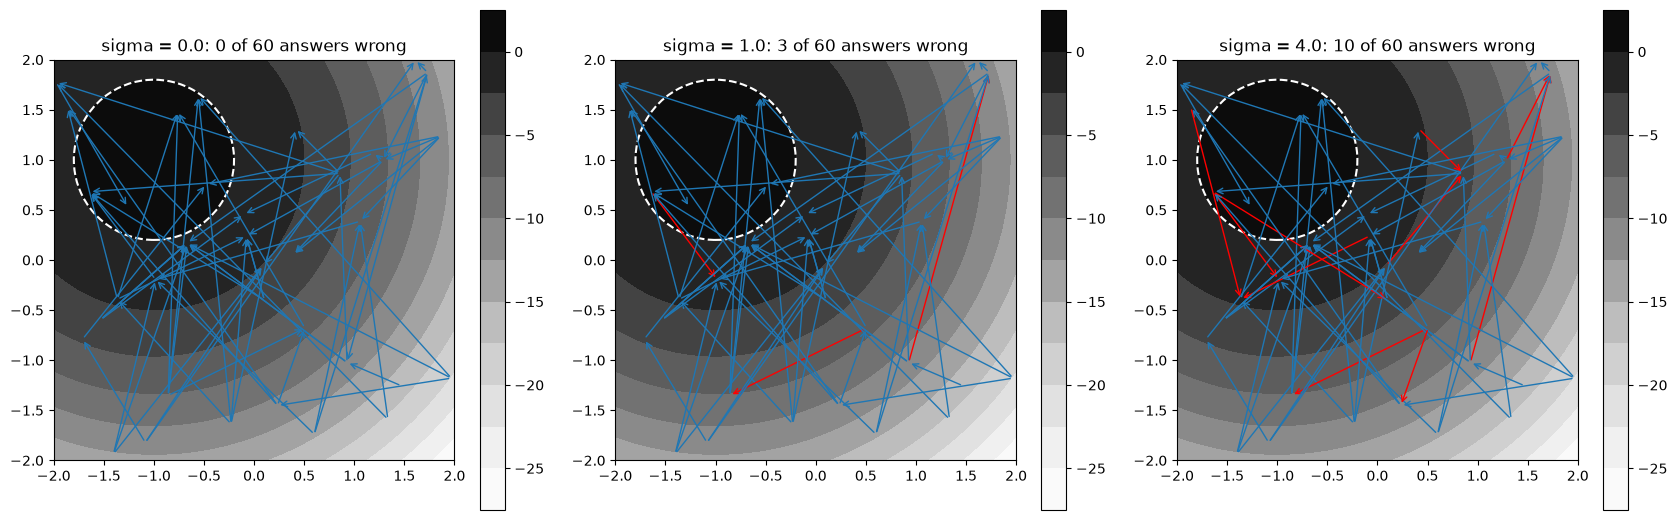

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5.3))
for axis, sigma in zip(axes, (0.0, 1.0, 4.0)):
    xa, xb, a_wins = make_comparisons(sigma, 60)
    winner, loser = np.where(a_wins[:, None], xa, xb), np.where(a_wins[:, None], xb, xa)
    wrong = utility(winner) < utility(loser)
    draw(axis, utility(X_map), f"sigma = {sigma}: {wrong.sum()} of 60 answers wrong", "Greys", 12)
    for w, l, bad in zip(winner, loser, wrong):
        axis.annotate("", xy=w, xytext=l, arrowprops=dict(arrowstyle="->", color="red" if bad else "tab:blue", lw=1))
    axis.set(xlim=(-2, 2), ylim=(-2, 2))
plt.tight_layout()
plt.show()

## 3. Utility learned by the PairwiseGP

Comparisons of the same pairs, different `sigma`. Learned utility (GP mean) next to the truth, and the rank correlation of learned vs true utility on 1000 random designs (1 = same ranking). The white dashed line is $u = 0$.

In [4]:
sigmas = (0.0, 0.5, 1.0, 2.0, 4.0)


## 10 comparisons

In [5]:
# fits = {sigma: fit(*make_comparisons(sigma, 10)) for sigma in sigmas}
# fig, axes = plt.subplots(2, 3, figsize=(16, 9.5))
# draw(axes[0, 0], utility(X_map), "true utility")
# for axis, (sigma, gp) in zip(axes.ravel()[1:], fits.items()):
#     draw(axis, gp.predict(X_map)[0], f"learned, sigma = {sigma}")
# fig.suptitle("Learned utility, 10 comparisons", fontsize=16)
# plt.tight_layout()
# plt.show()

## 30 comparisons

In [6]:
# fits = {sigma: fit(*make_comparisons(sigma, 30)) for sigma in sigmas}
# fig, axes = plt.subplots(2, 3, figsize=(16, 9.5))
# draw(axes[0, 0], utility(X_map), "true utility")
# for axis, (sigma, gp) in zip(axes.ravel()[1:], fits.items()):
#     draw(axis, gp.predict(X_map)[0], f"learned, sigma = {sigma}")
# fig.suptitle("Learned utility, 30 comparisons", fontsize=16)
# plt.tight_layout()
# plt.show()

## 100 comparisons

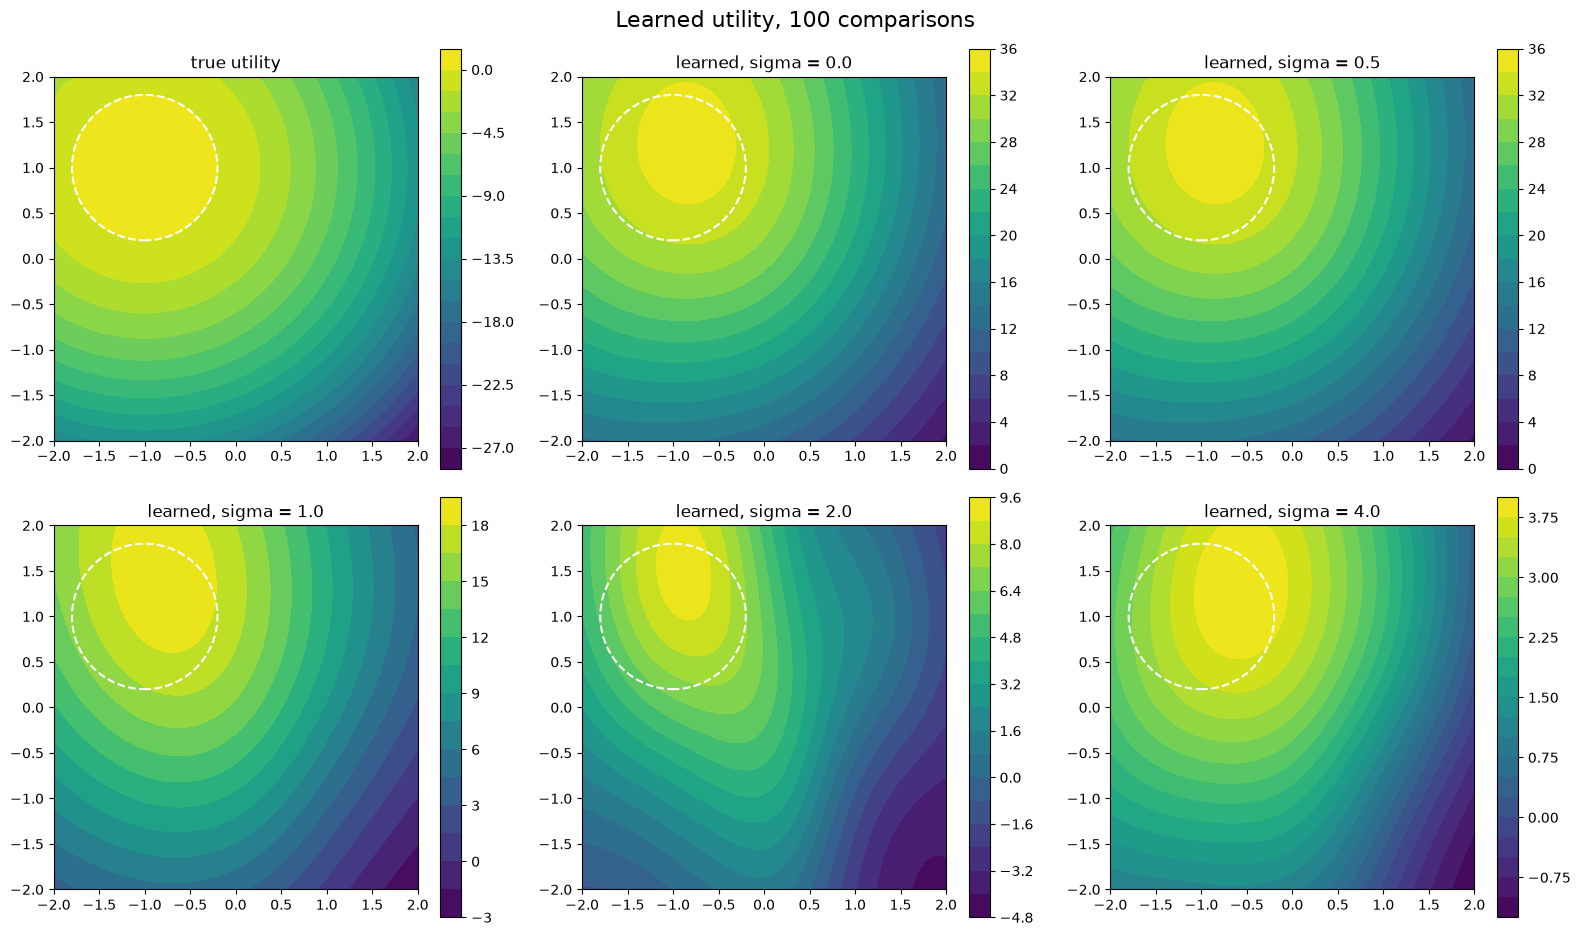

In [7]:
fits = {sigma: fit(*make_comparisons(sigma, 100)) for sigma in sigmas}
fig, axes = plt.subplots(2, 3, figsize=(16, 9.5))
draw(axes[0, 0], utility(X_map), "true utility")
for axis, (sigma, gp) in zip(axes.ravel()[1:], fits.items()):
    draw(axis, gp.predict(X_map)[0], f"learned, sigma = {sigma}")
fig.suptitle("Learned utility, 100 comparisons", fontsize=16)
plt.tight_layout()
plt.show()

## 4. The score $\pi(x) = \mathbb{E}[\Phi(u(x))]$ the loop uses, with noise

Same fits: `PreferenceGP.prob_torch` against the truth $\Phi(u)$.

In [8]:
gp.posterior(xa).mean.max()
max_u = gp.posterior(xa).mean.max()
print(max_u)
print(gp.posterior(xa).mean)

tensor(3.9292, dtype=torch.float64, grad_fn=<MaxBackward1>)
tensor([[ 3.5014],
        [ 3.5197],
        [ 2.5427],
        [ 3.3512],
        [ 1.8969],
        [ 2.5134],
        [ 3.1272],
        [ 3.3512],
        [ 1.3487],
        [ 0.7992],
        [ 1.5313],
        [ 0.9064],
        [ 2.9546],
        [ 3.5014],
        [ 3.9292],
        [ 1.5313],
        [ 3.3512],
        [ 1.1953],
        [ 1.8969],
        [ 0.7992],
        [ 1.1953],
        [ 1.1307],
        [ 1.7674],
        [ 1.5313],
        [ 2.5032],
        [ 1.8758],
        [ 3.5014],
        [ 3.9292],
        [ 3.1209],
        [ 3.3512],
        [ 3.3512],
        [ 2.6105],
        [ 2.6877],
        [ 0.7078],
        [ 2.7838],
        [-0.2893],
        [ 0.6256],
        [ 0.9064],
        [ 0.7992],
        [ 2.6877],
        [ 2.9546],
        [ 1.7674],
        [ 1.4176],
        [ 2.7721],
        [ 1.4176],
        [ 1.9796],
        [ 0.7078],
        [ 2.2363],
        [ 1.9796],
        [

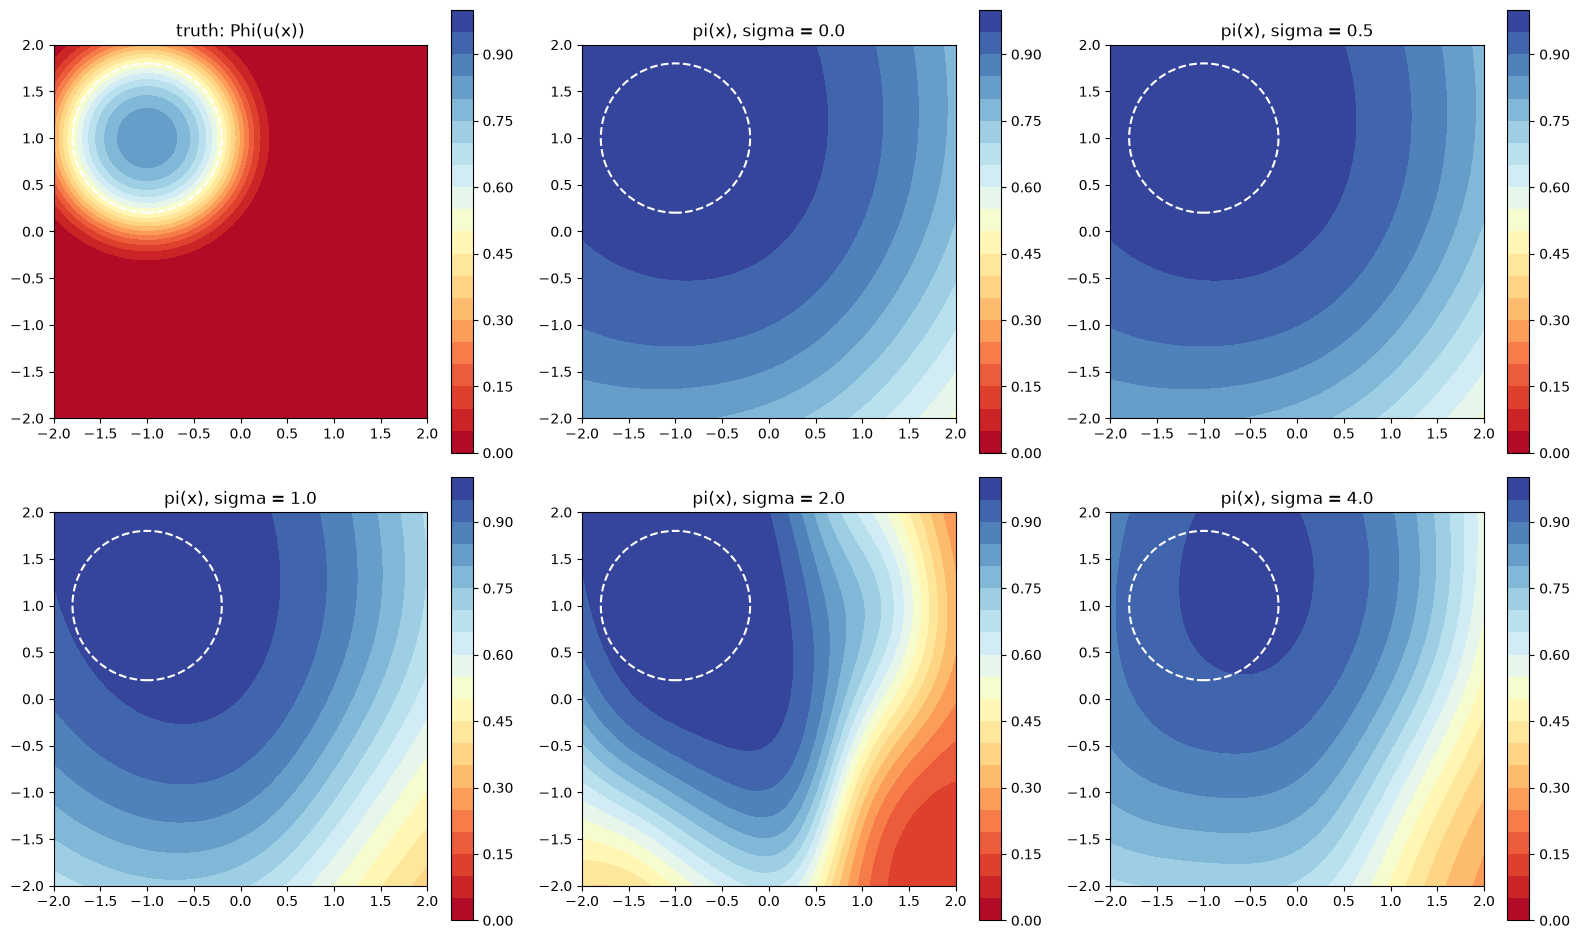

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9.5))
levels = np.linspace(0, 1, 21)
draw(axes[0, 0], norm.cdf(utility(X_map)), "truth: Phi(u(x))", "RdYlBu", levels)
for axis, (sigma, gp) in zip(axes.ravel()[1:], fits.items()):
    draw(axis, gp.prob_torch(X_map).detach().numpy(), f"pi(x), sigma = {sigma}", "RdYlBu", levels)
plt.tight_layout()
plt.show()


# # the same maps with a softmax over the box instead of Phi
# def relative_score(values):
#     """Standardise over the grid (mean 0, sd 1), then exp(value - max): 1 at the best point of the grid, lower elsewhere."""
#     standardised = (values - values.mean()) / values.std()
#     return np.exp(standardised - standardised.max())

# def relative_score(values, max_u):
#     values = np.asarray(values)
#     standardised = (values - values.mean()) / values.std()
#     return norm.cdf(((standardised) - max_u) / (np.sqrt(2)*1e-03))

# max_polynomial_utility = utility(X_map).max()

# fig, axes = plt.subplots(2, 3, figsize=(16, 9.5))
# panels = list(axes.flat)
# # draw(panels[0], relative_score(utility(X_map, max_polynomial_utility)), "truth: softmax of standardised u", "RdYlBu", levels)
# for panel, sigma in zip(panels[1:], fits):
#     learned_mean, _ = fits[sigma].predict(X_map)
#     max_u = fits[sigma].predict(xa)[0].max()
#     draw(panel, relative_score(learned_mean, max_u), f"softmax of standardised m, sigma = {sigma}", "viridis", levels)
# plt.tight_layout()
# plt.show()

# # check of prob_torch: Phi computed by hand from predict (mean m, variance v), and the plug-in Phi(m), which ignores v
# fig, axes = plt.subplots(2, 3, figsize=(16, 9.5))
# panels = list(axes.flat)
# draw(panels[0], norm.cdf(utility(X_map)), "truth: Phi(u(x))", "RdYlBu", levels)
# print(f"{'sigma':>5s} {'max |prob_torch - Phi(m/sqrt(1+v))|':>38s} {'max |prob_torch - Phi(m)|':>27s} {'share of the box differing by > 0.05':>38s}")
# for panel, sigma in zip(panels[1:], fits):
#     m, v = fits[sigma].predict(X_map)
#     by_hand = norm.cdf(m / np.sqrt(1 + v))                     # E[Phi(g)], g ~ N(m, v)
#     plug_in = norm.cdf(m)                                      # probit of the mean only
#     from_code = fits[sigma].prob_torch(X_map).detach().numpy()
#     draw(panel, plug_in, f"plug-in Phi(m), sigma = {sigma}", "RdYlBu", levels)
#     print(f"{sigma:5.1f} {abs(from_code - by_hand).max():38.1e} {abs(from_code - plug_in).max():27.3f} {np.mean(abs(from_code - plug_in) > 0.05):38.0%}")
# plt.tight_layout()
# plt.show()

### Soft-Copeland score (González et al. 2017, eq. 5)

$C(x) = \frac{1}{M}\sum_{k=1}^{M} \pi(x \succ x_k)$: the average probability that $x$ beats the landmarks $x_1,\dots,x_M$, drawn **once**, uniformly in the problem's bounds, and then kept fixed (feasibility of the landmarks does not matter). Learned by the `PreferenceGP` (`soft_copeland_torch`: one joint posterior, no loops); the truth panel uses the true utility on the same landmarks. Star: the maximiser on the grid, the Condorcet winner.

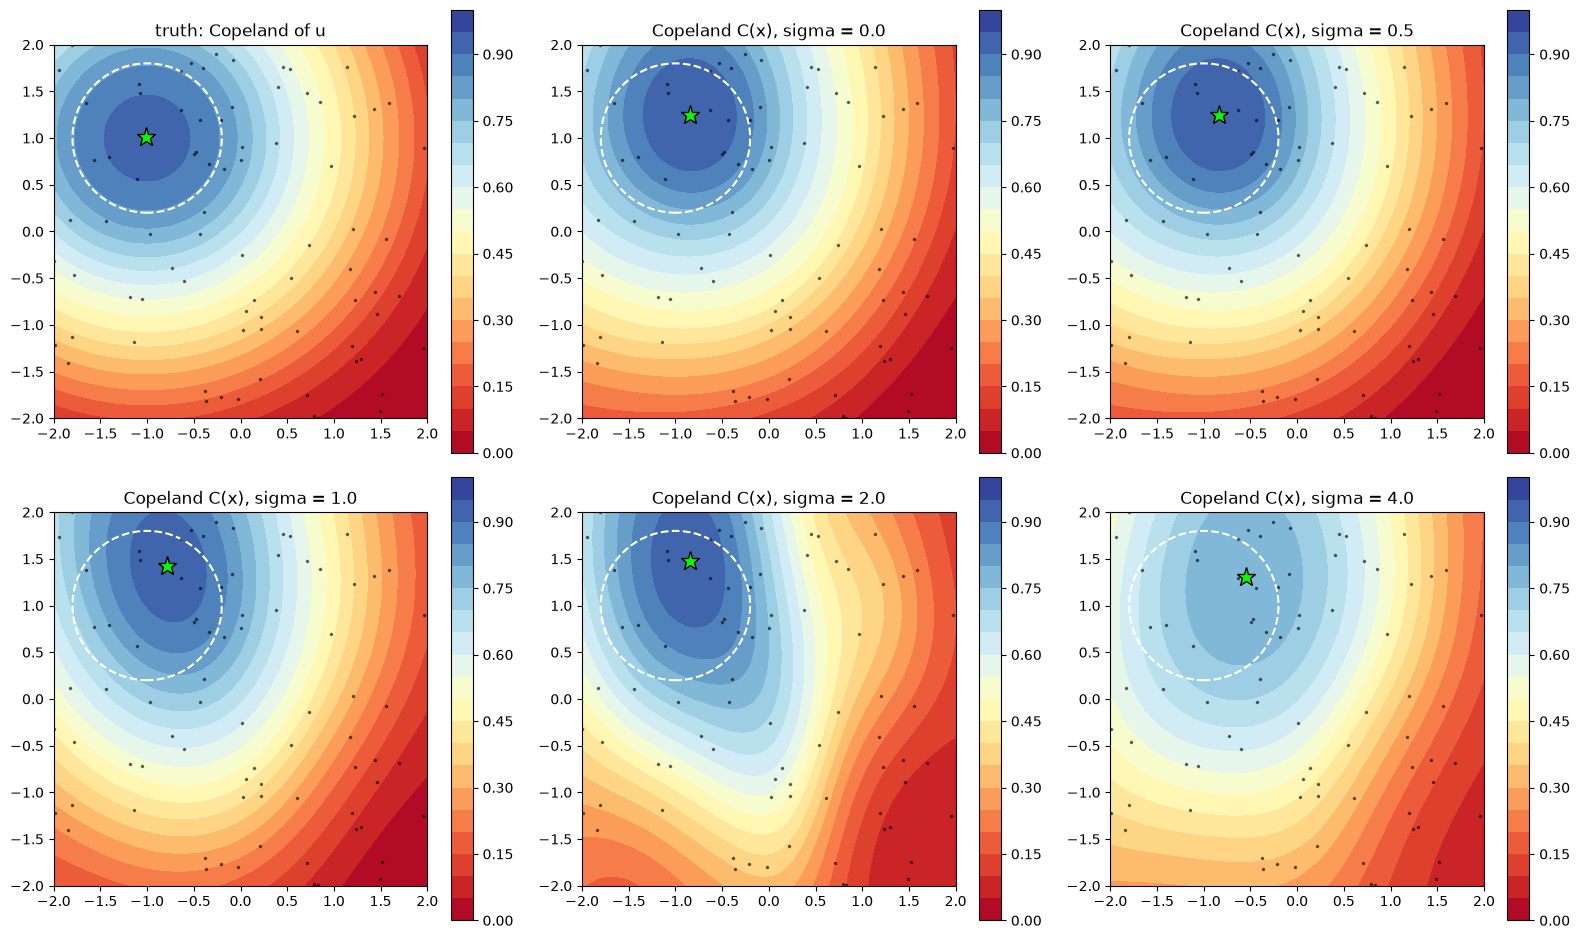

In [10]:
n_landmarks = 80
landmarks = initial_design(ROSEN_BOUNDS, n_landmarks, "random", seed=5)      # fixed once: uniform in the problem's bounds

true_copeland = norm.cdf((utility(X_map)[:, None] - utility(landmarks)[None, :]) / np.sqrt(2)).mean(axis=1)

fig, axes = plt.subplots(2, 3, figsize=(16, 9.5))
levels = np.linspace(0, 1, 21)
draw(axes[0, 0], true_copeland, "truth: Copeland of u", "RdYlBu", levels)
for axis, (sigma, gp) in zip(axes.ravel()[1:], fits.items()):
    copeland = gp.soft_copeland_torch(X_map, landmarks).detach().numpy()
    draw(axis, copeland, f"Copeland C(x), sigma = {sigma}", "RdYlBu", levels)
    axis.plot(*X_map[copeland.argmax()], "*", color="lime", ms=14, mec="k")
axes[0, 0].plot(*X_map[true_copeland.argmax()], "*", color="lime", ms=14, mec="k")
for axis in axes.ravel():
    axis.plot(*landmarks.T, ".", color="k", ms=3, alpha=0.5)
plt.tight_layout()
plt.show()

For each fit, on 1000 random designs: the range of the learned mean $m$, the share of designs with $m > 0$ (versus the share with true $u > 0$), the smallest and median $\pi$, and the median posterior sd of the utility.

In [12]:
print(f"true utility on the 1000 test designs: min {utility(test_X).min():.1f}, median {np.median(utility(test_X)):.1f}, "
      f"max {utility(test_X).max():.1f};  share with u > 0: {np.mean(utility(test_X) > 0):.0%}\n")
print(f"{'sigma':>5s} {'m min':>8s} {'m median':>9s} {'m max':>8s} {'m > 0':>7s} {'pi min':>7s} {'pi median':>10s} {'pi > 0.6':>9s} {'sd of u':>8s}")
for sigma, gp in fits.items():
    mean, var = gp.predict(test_X)
    pi = gp.prob_torch(test_X).detach().numpy()
    print(f"{sigma:5.1f} {mean.min():8.1f} {np.median(mean):9.1f} {mean.max():8.1f} {np.mean(mean > 0):7.0%} {pi.min():7.2f} "
          f"{np.median(pi):10.2f} {np.mean(pi > 0.6):9.0%} {np.sqrt(np.median(var)):8.2f}")

true utility on the 1000 test designs: min -26.7, median -5.2, max 1.0;  share with u > 0: 13%

sigma    m min  m median    m max   m > 0  pi min  pi median  pi > 0.6  sd of u
  0.0      1.9      23.5     35.1    100%    0.55       0.92       99%    16.54
  0.5      1.9      23.5     35.1    100%    0.55       0.92       99%    16.54
  1.0     -2.6      10.7     19.1     98%    0.38       0.88       94%     8.88
  2.0     -4.1       2.7      9.2     77%    0.10       0.80       70%     2.94
  4.0     -1.2       2.3      4.0     92%    0.29       0.86       87%     1.90


**The steps from the GP to $\pi$.** Rows: noise level. Columns: the learned mean $m(x)$ of the utility; its posterior sd $\sqrt v$; $z = m / \sqrt{1 + v}$; and $\pi = \Phi(z)$. White dashed: true $u = 0$. Black: $m = 0$, where $\pi = 0.5$. Where the colourbar of $m$ does not contain 0, $\pi$ is above 0.5 everywhere.

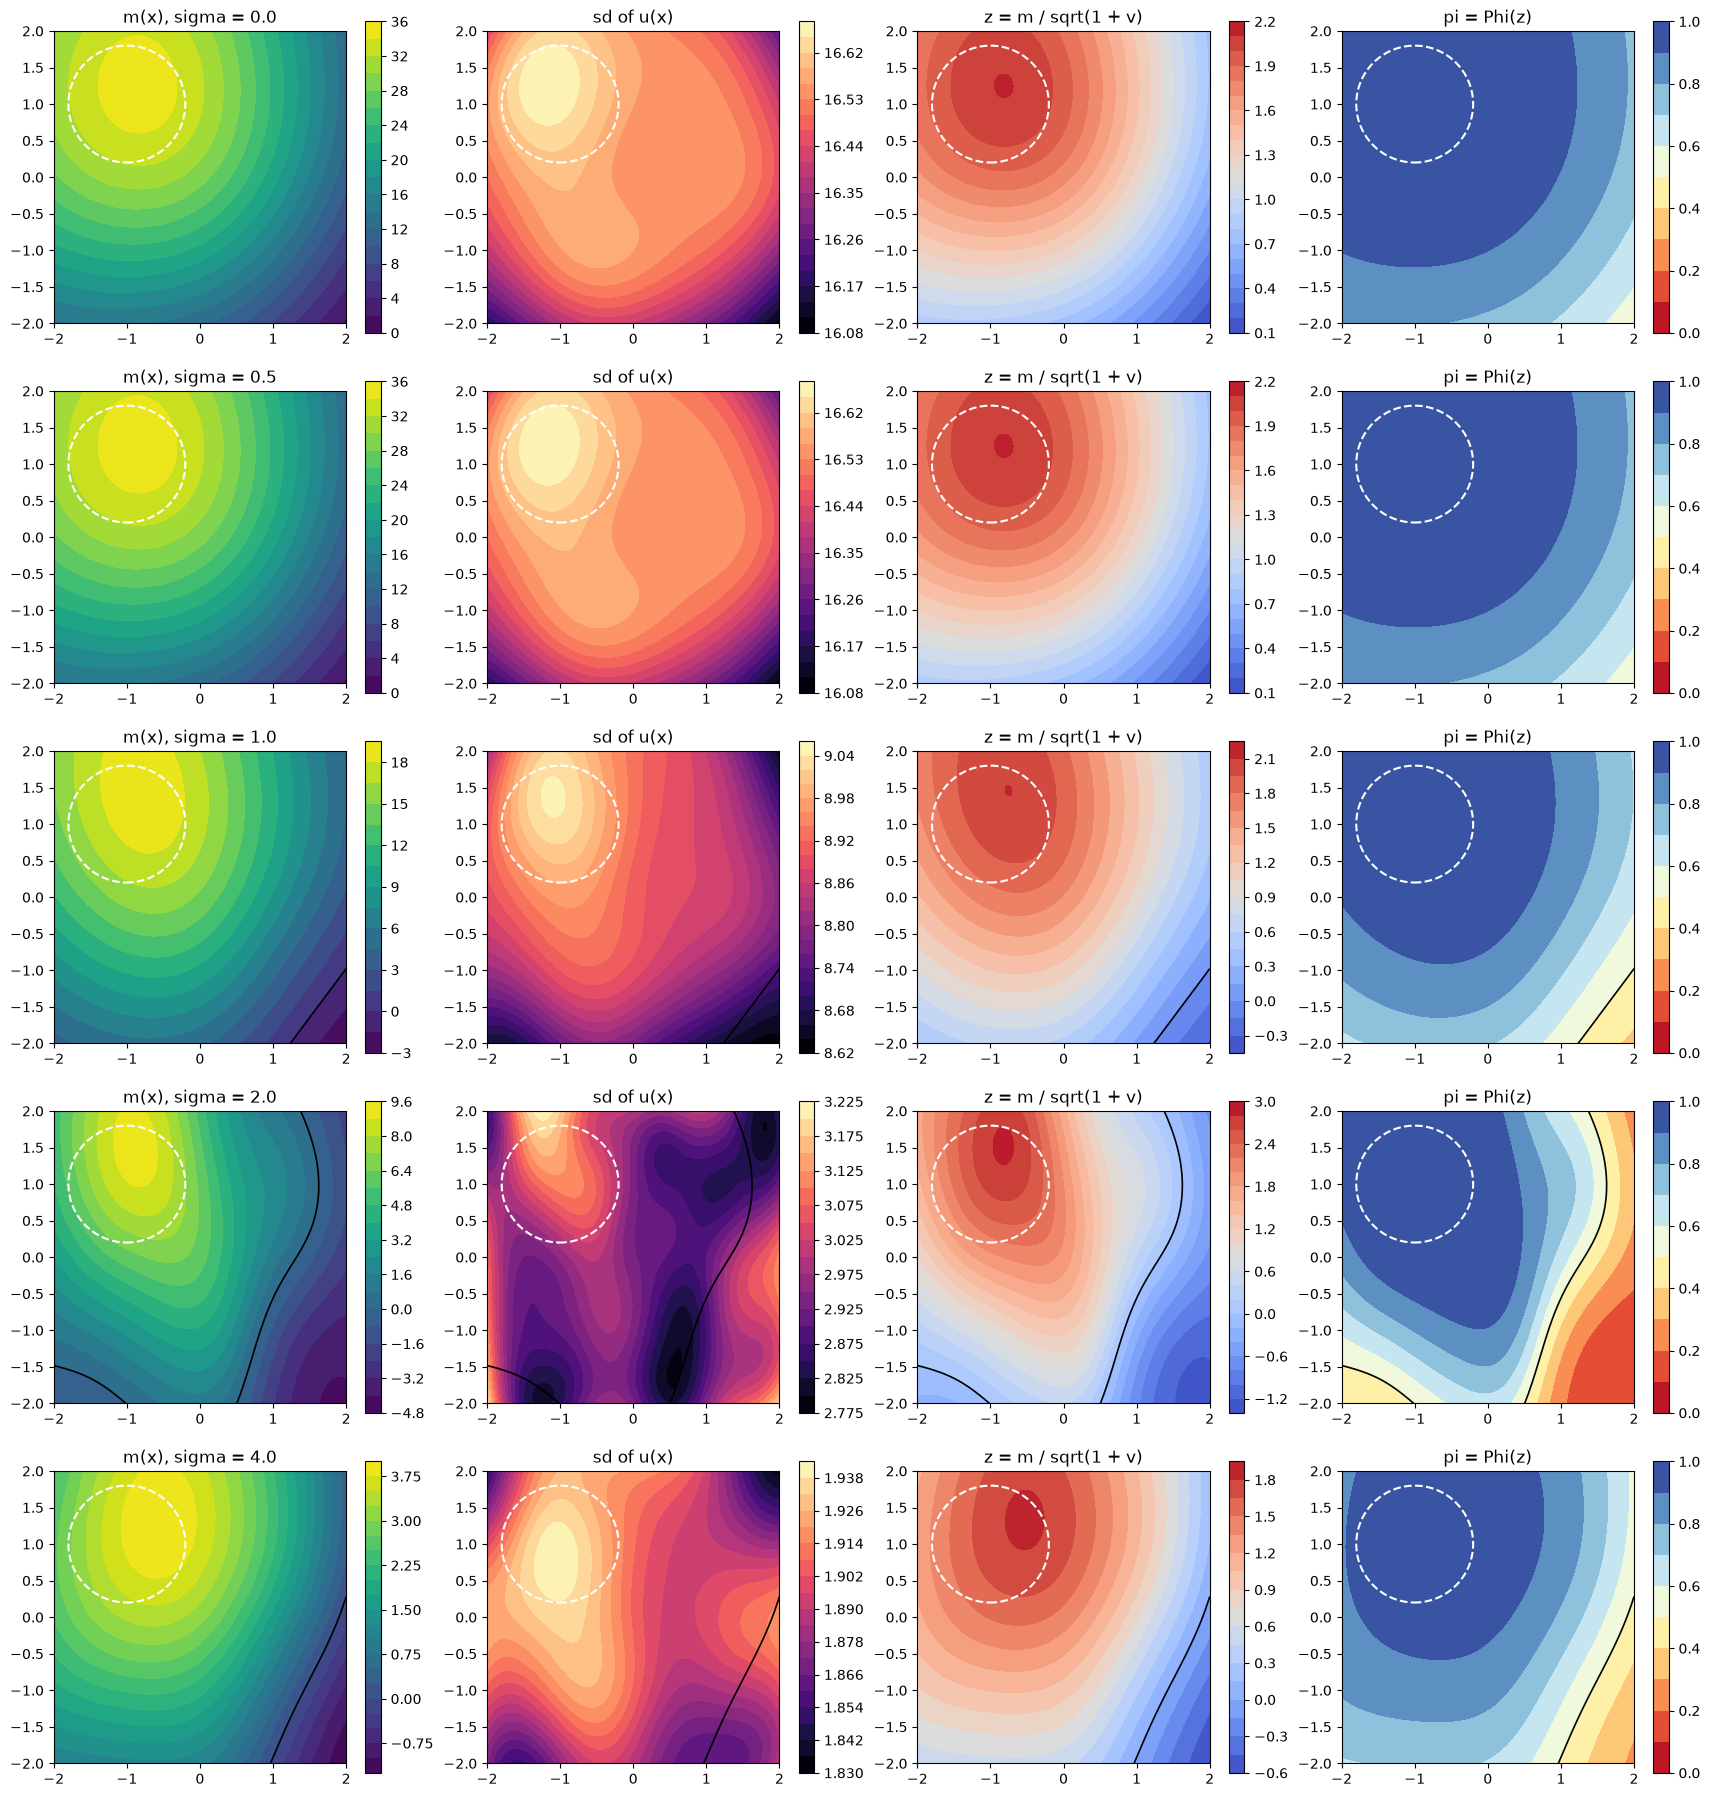

In [13]:
fig, axes = plt.subplots(len(fits), 4, figsize=(17, 3.6 * len(fits)), layout="constrained")
for row, (sigma, gp) in zip(axes, fits.items()):
    mean, var = gp.predict(X_map)
    z = mean / np.sqrt(1 + var)
    draw(row[0], mean, f"m(x), sigma = {sigma}")
    draw(row[1], np.sqrt(var), "sd of u(x)", "magma")
    draw(row[2], z, "z = m / sqrt(1 + v)", "coolwarm")
    draw(row[3], norm.cdf(z), "pi = Phi(z)", "RdYlBu", np.linspace(0, 1, 11))
    for axis in row:
        axis.contour(map_x1, map_x2, mean.reshape(map_x1.shape), [0], colors="k", linewidths=1.2)
plt.show()

## 5. Noise vs number of comparisons

Rank correlation (learned vs true utility, 1000 designs) as comparisons accumulate, median of 5 seeds.

In [14]:
counts = (10, 20, 40, 80, 160)
plt.figure(figsize=(6.5, 4.4))
for sigma in sigmas:
    rho = np.array([[spearmanr(utility(test_X), fit(*make_comparisons(sigma, n, seed=s)).predict(test_X)[0])[0]
                     for n in counts] for s in range(5)])
    plt.plot(counts, np.median(rho, 0), "o-", label=f"sigma = {sigma}")
plt.xscale("log"); plt.xlabel("comparisons"); plt.ylabel("rank correlation"); plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

KeyboardInterrupt: 

<Figure size 650x440 with 0 Axes>

## 6. One dimension: certainty about "x beats y"

A 1-d utility on $[0, 3]$, `u(x) = sin(3x) + x/2`. The DM compares random pairs with noise `sigma`.

In [15]:
BOUNDS_1D = [[0.0, 3.0]]
utility_1d = lambda x: np.sin(3 * np.asarray(x).reshape(-1)) + 0.5 * np.asarray(x).reshape(-1)


def make_comparisons_1d(sigma, n_comparisons, n_designs=30, seed=3):
    rng = np.random.default_rng(seed)
    designs = rng.uniform(*BOUNDS_1D[0], (n_designs, 1))
    first = rng.integers(0, n_designs, n_comparisons)
    second = (first + rng.integers(1, n_designs, n_comparisons)) % n_designs
    noise = sigma * rng.standard_normal((2, n_comparisons))
    first_wins = utility_1d(designs[first]) + noise[0] > utility_1d(designs[second]) + noise[1]
    return designs[first], designs[second], first_wins


def fit_1d(sigma, n_comparisons, seed=3):
    return PreferenceGP(bounds=BOUNDS_1D, link="probit").fit(*make_comparisons_1d(sigma, n_comparisons, seed=seed))


def prob_first_better(gp, xa, xb):  
    """For pairs (xa[j], xb[j]): the median Phi(m / sqrt 2) of the latent probability Phi((g(xa) - g(xb)) / sqrt 2), and its
    band Phi((m -+ 2 s) / sqrt 2), where m, s are the mean and sd of the latent difference g(xa) - g(xb)."""
    pairs = torch.as_tensor(np.stack([xa, xb], axis=1), dtype=torch.float64)           # (n, 2, 1)
    posterior = gp.model.posterior(pairs)
    mean, cov = posterior.mean.squeeze(-1).detach(), posterior.mvn.covariance_matrix.detach()
    diff_mean = (mean[:, 0] - mean[:, 1]).numpy()
    diff_var = (cov[:, 0, 0] + cov[:, 1, 1] - 2 * cov[:, 0, 1]).clamp_min(0).numpy()
    diff_sd = np.sqrt(diff_var)
    return (norm.cdf(diff_mean / np.sqrt(2)),
        norm.cdf((diff_mean - 2 * diff_sd) / np.sqrt(2)), norm.cdf((diff_mean + 2 * diff_sd) / np.sqrt(2)))



x_line = np.linspace(*BOUNDS_1D[0], 200)[:, None]

### 6a. Learned utility, noise level vs number of comparisons

Fixed reference design $y = 1.0$ (triangle). Blue: the median of the GP's $P(x \succ y)$ with a $\pm 2$ sd band from the GP's uncertainty about the difference; black: what the noisy DM would answer, $\Phi\big((u(x) - u(y))/(\sqrt2\sigma)\big)$. Ticks at the bottom: the compared designs. The band is narrow where the GP is sure; a prediction is "sure" when the band stays above 0.9 or below 0.1 (dotted).

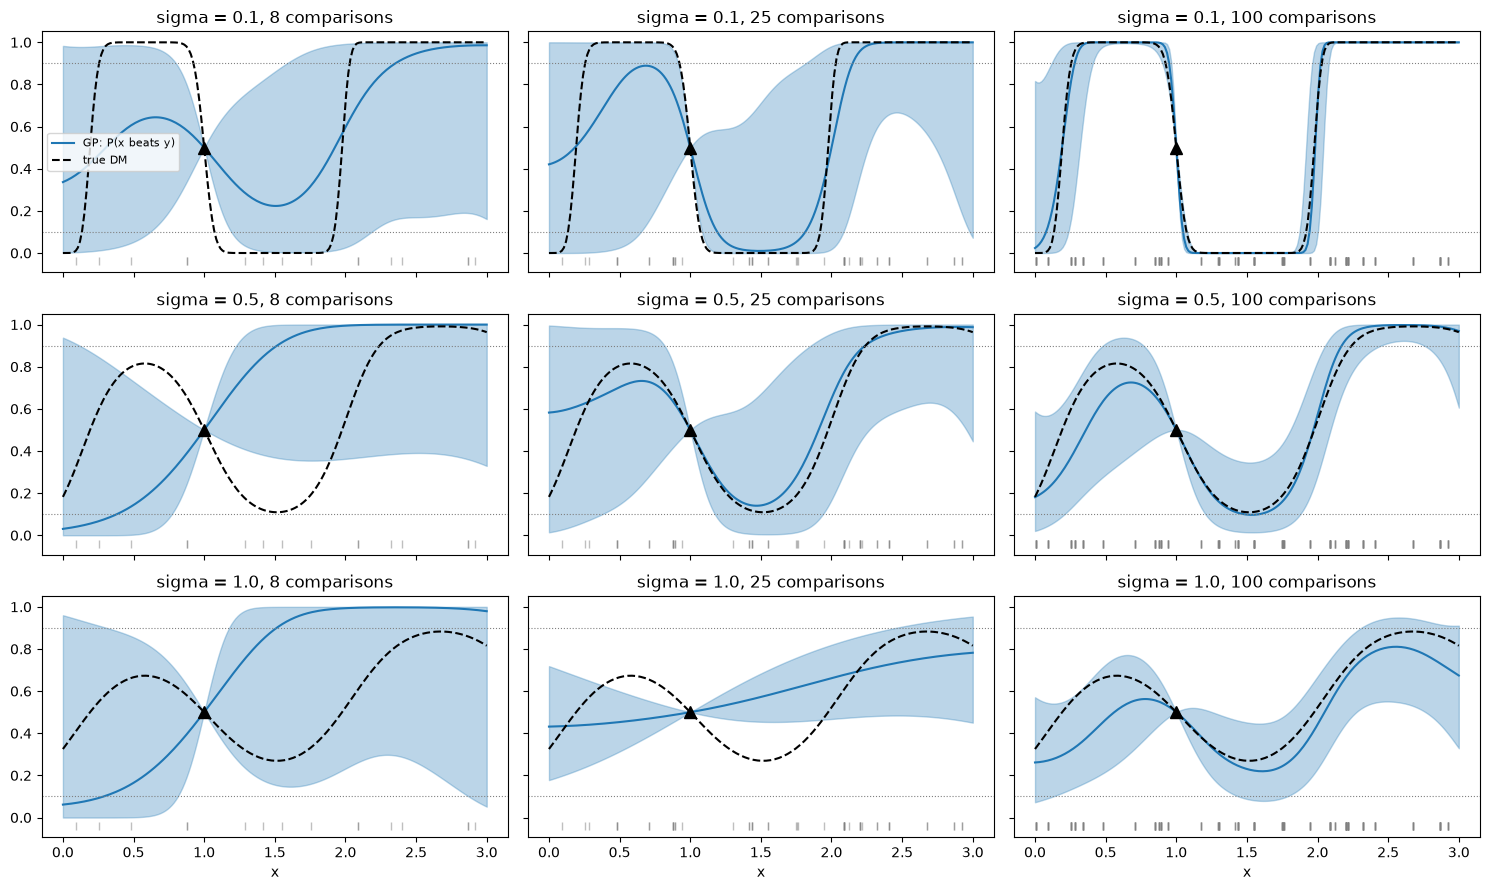

In [16]:
reference = np.array([[1.0]])
sigmas_1d, counts_1d = (0.1, 0.5, 1.0), (8, 25, 100)
fig, axes = plt.subplots(len(sigmas_1d), len(counts_1d), figsize=(15, 9), sharex=True, sharey=True)
for row, sigma in zip(axes, sigmas_1d):
    for axis, n in zip(row, counts_1d):
        xa, xb, a_wins = make_comparisons_1d(sigma, n)
        gp = PreferenceGP(bounds=BOUNDS_1D, link="probit").fit(xa, xb, a_wins)
        mid, low, high = prob_first_better(gp, x_line, np.repeat(reference, len(x_line), 0))
        axis.fill_between(x_line[:, 0], low, high, color="tab:blue", alpha=0.3)
        axis.plot(x_line[:, 0], mid, color="tab:blue", label="GP: P(x beats y)")
        axis.plot(x_line[:, 0], norm.cdf((utility_1d(x_line) - utility_1d(reference)) / (np.sqrt(2) * sigma)),
                  "k--", label="true DM")
        axis.plot(reference[:, 0], 0.5, "k^", ms=9)
        axis.plot(np.r_[xa[:, 0], xb[:, 0]], np.full(2 * n, -0.04), "|", color="gray", alpha=0.5)
        for level in (0.1, 0.9):
            axis.axhline(level, color="gray", ls=":", lw=0.8)
        axis.set_title(f"sigma = {sigma}, {n} comparisons")
axes[0, 0].legend(fontsize=8, loc="center left")
for axis in axes[-1]:
    axis.set_xlabel("x")
plt.tight_layout()
plt.show()

### 6b. Pairs $(x, y)$: how sure is the GP that $x \succ y$?

For every pair of designs on the line, $P(x \succ y)$ and the width of its $\pm 2$ sd band, for one setting ($\sigma = 0.5$) and 10, 30 and 100 comparisons. Right: the pairs where the GP is **sure** (band entirely above 0.9 or below 0.1) coloured by whether it is **right** with respect to the noise-free truth $u(x) > u(y)$.

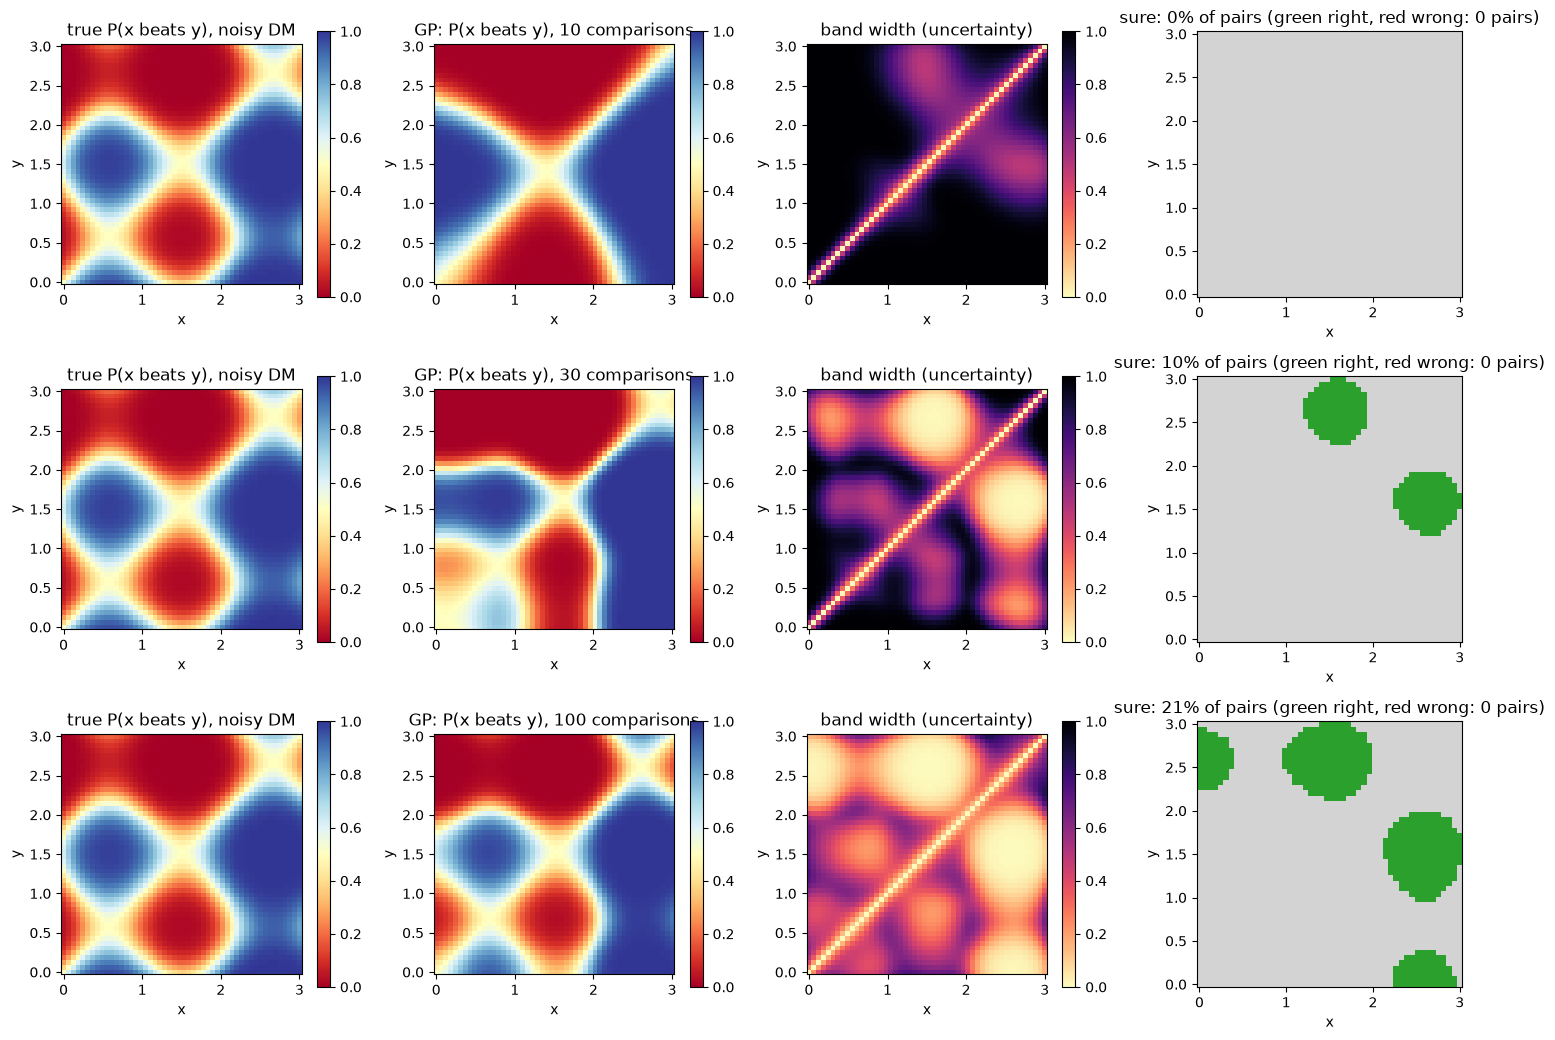

In [17]:
sigma_pairs = 0.5
grid = np.linspace(*BOUNDS_1D[0], 50)
pair_x, pair_y = np.meshgrid(grid, grid)
xa_pairs, xb_pairs = pair_x.reshape(-1, 1), pair_y.reshape(-1, 1)
truth_noisy = norm.cdf((utility_1d(xa_pairs) - utility_1d(xb_pairs)) / (np.sqrt(2) * sigma_pairs)).reshape(pair_x.shape)
true_order = (utility_1d(xa_pairs) > utility_1d(xb_pairs)).reshape(pair_x.shape)

fig, axes = plt.subplots(3, 4, figsize=(15, 10.5))
for row, n in zip(axes, (10, 30, 100)):
    gp = fit_1d(sigma_pairs, n)
    mid, low, high = (a.reshape(pair_x.shape) for a in prob_first_better(gp, xa_pairs, xb_pairs))
    sure = (low > 0.9) | (high < 0.1)
    wrong = sure & ((mid > 0.5) != true_order)
    panels = ((truth_noisy, "true P(x beats y), noisy DM", "RdYlBu", (0, 1)),
              (mid, f"GP: P(x beats y), {n} comparisons", "RdYlBu", (0, 1)),
              (high - low, "band width (uncertainty)", "magma_r", (0, 1)))
    for axis, (values, title, cmap, (vmin, vmax)) in zip(row[:3], panels):
        shown = axis.pcolormesh(pair_x, pair_y, values, cmap=cmap, vmin=vmin, vmax=vmax, shading="auto")
        fig.colorbar(shown, ax=axis)
        axis.set_title(title)
    colour = np.where(sure, np.where(wrong, 2.0, 1.0), 0.0)
    row[3].pcolormesh(pair_x, pair_y, colour, cmap=plt.matplotlib.colors.ListedColormap(["lightgray", "tab:green", "tab:red"]),
                      vmin=-0.5, vmax=2.5, shading="auto")
    row[3].set_title(f"sure: {sure.mean():.0%} of pairs (green right, red wrong: {wrong.sum()} pairs)")
    for axis in row:
        axis.set(xlabel="x", ylabel="y", aspect="equal")
plt.tight_layout()
plt.show()

## 7. The BO loop on Rosenbrock: log EI, then log EI + log $\pi$

`BayesianOptimizer` maximises `LogEIProduct`: log EI of the objective GP, plus log PoF of each constraint (none here), plus log $\pi$ of the preference GP. Without a DM there is no preference GP, the last term is 0 and the acquisition is plain log EI. With a DM, 30 pairs of 30 designs are compared once, before the start, with noise `sigma` = 0.5, and one `PreferenceGP` is fitted to the answers. Same seed, 25 BO steps. Green star: the maximum of $f$ over the box, $(1, 1)$. Magenta cross: the maximum of $f$ among the designs the DM accepts ($u > 0$, magenta dotted line), found on a grid.

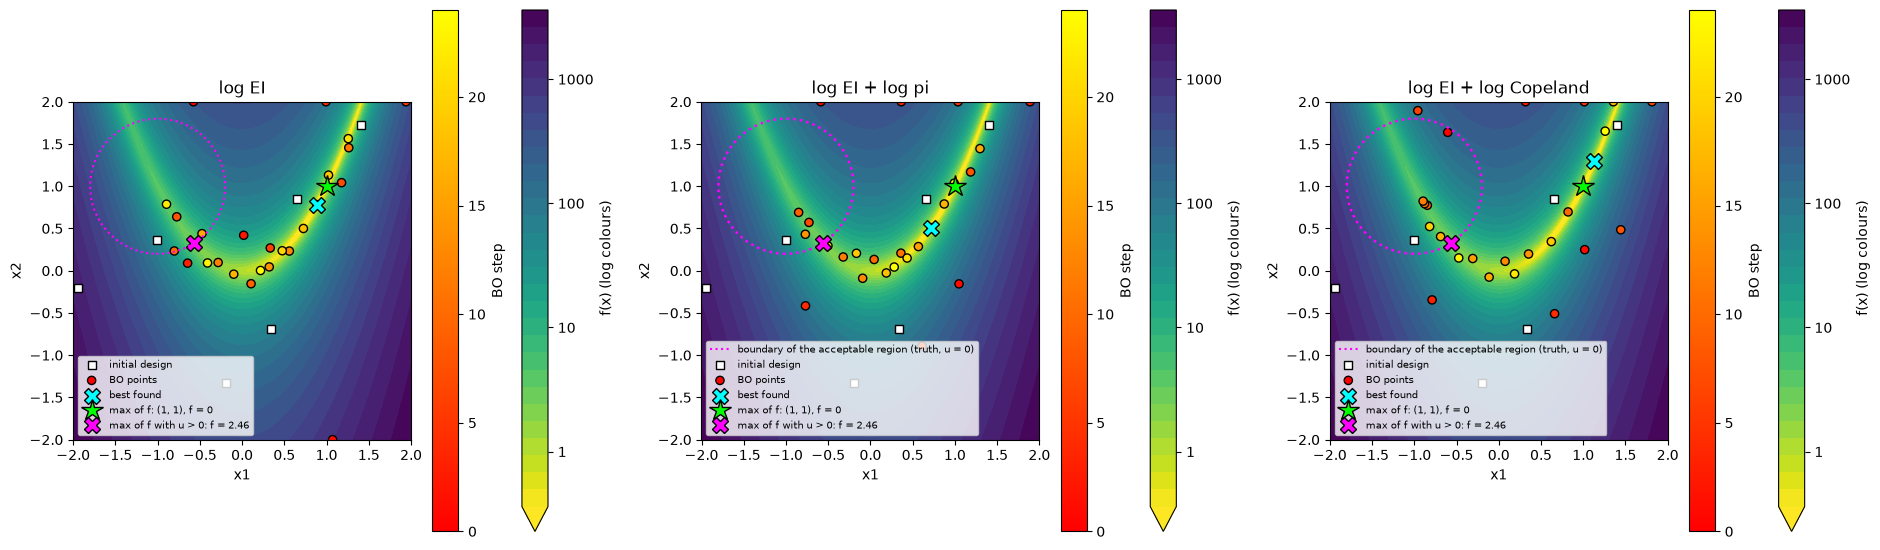

max of f: 0.0000 at (1, 1);  max of f with u > 0: 2.4608 at [-0.565  0.33 ]
log EI                 BO points with u > 0:  16%;  best f among designs with u > 0: 3.3020
log EI + log pi        BO points with u > 0:  12%;  best f among designs with u > 0: 3.1590
log EI + log Copeland  BO points with u > 0:  24%;  best f among designs with u > 0: 3.3424


In [18]:
from BOproj.benchmarks import grid_optimum, neg_rosenbrock, rosenbrock
from BOproj.bo_loop import BayesianOptimizer

x_acceptable, f_acceptable = grid_optimum(neg_rosenbrock, ROSEN_BOUNDS, accept=lambda X: utility(X) > 0)   # f is maximised: f_acceptable <= 0
n_bo_steps = 25
plain = BayesianOptimizer(neg_rosenbrock, ROSEN_BOUNDS, seed=0).run(n_bo_steps)
with_preference = BayesianOptimizer(neg_rosenbrock, ROSEN_BOUNDS, seed=0, comparer=NoisyPairwiseLabeler(utility, sigma=0.5),
                                    X_pref=initial_design(ROSEN_BOUNDS, 30, "lhs", seed=7)).run(n_bo_steps)
with_copeland = BayesianOptimizer(neg_rosenbrock, ROSEN_BOUNDS, seed=0, comparer=NoisyPairwiseLabeler(utility, sigma=0.5),
                                  X_pref=initial_design(ROSEN_BOUNDS, 30, "lhs", seed=7),
                                  preference_score="copeland", n_landmarks=64).run(n_bo_steps)



def mark_optima(axis):
    axis.plot(1, 1, "*", color="lime", ms=16, mec="k", label="max of f: (1, 1), f = 0")
    axis.plot(*x_acceptable, "X", color="magenta", ms=11, mec="k", label=f"max of f with u > 0: f = {-f_acceptable:.2f}")
    axis.legend(fontsize=7, loc="lower left")


fig, axes = plt.subplots(1, 3, figsize=(19, 5.6))
for axis, run, name in zip(axes, (plain, with_preference, with_copeland), ("log EI", "log EI + log pi", "log EI + log Copeland")):
    run.plot_points(ax=axis, background=rosenbrock, background_label="f(x)", background_scale="log", title=name)
    mark_optima(axis)
axes[0].contour(map_x1, map_x2, utility(X_map).reshape(map_x1.shape), [0], colors="magenta", linestyles=":")   # plot_points draws it itself when there is a DM
plt.tight_layout()
plt.show()
print(f"max of f: 0.0000 at (1, 1);  max of f with u > 0: {-f_acceptable:.4f} at {np.round(x_acceptable, 3)}")
for name, run in (("log EI", plain), ("log EI + log pi", with_preference), ("log EI + log Copeland", with_copeland)):
    accepted = utility(run.X) > 0
    print(f"{name:22s} BO points with u > 0: {np.mean(accepted[run.n_init:]):4.0%};  "
          f"best f among designs with u > 0: {-np.max(run.y[accepted]) if accepted.any() else float('nan'):.4f}")

### 7b. Looking inside the Copeland acquisition

Three seeds (each seed changes the DM's 30 answers, the landmarks and the BO start), only `log EI + log Copeland`.
1. **Check** that the vectorised `soft_copeland_torch` equals a plain numpy computation of eq. 5 from `predict` (mean and covariance), and a loop over `prob_better_torch`.
2. **Where the loop went:** the learned Copeland map $C(x)$ on the fixed landmarks (black dots), the initial design (white squares) and the BO candidates, numbered by step and coloured by order.
3. **Table of the chosen points:** true $u$, learned $C$ (the value the loop used), true $C$ of the utility on the same landmarks, log EI and the acquisition value there.
4. **Acquisition maps** at one step: log EI, log Copeland (drawn as "log pi") and their sum; red star = the point chosen.

In [ ]:
from IPython.display import display
from BOproj.benchmarks import neg_rosenbrock
from BOproj.bo_loop import BayesianOptimizer

copeland_runs = {seed: BayesianOptimizer(neg_rosenbrock, ROSEN_BOUNDS, seed=seed, comparer=NoisyPairwiseLabeler(utility, sigma=0.5),
                                         X_pref=initial_design(ROSEN_BOUNDS, 30, "lhs", seed=7),
                                         preference_score="copeland", n_landmarks=64).run(n_bo_steps)
                 for seed in (0, 1, 2)}


def true_copeland_of(X, landmarks):
    """Eq. 5 with the true utility: mean over the landmarks of Phi((u(x) - u(x_k)) / sqrt 2)."""
    return norm.cdf((utility(X)[:, None] - utility(landmarks)[None, :]) / np.sqrt(2)).mean(axis=1)


# 1. is the vectorised score right?  (numpy version of eq. 5 from predict, and a loop over prob_better_torch)
run = copeland_runs[0]
check_X = initial_design(ROSEN_BOUNDS, 6, "random", seed=1)
mean, covariance = run.preference_gp.predict(np.vstack([check_X, run.landmarks]), full_cov=True)
n_check = len(check_X)
diff_mean = mean[:n_check, None] - mean[None, n_check:]
diff_var = np.diag(covariance)[:n_check, None] + np.diag(covariance)[None, n_check:] - 2 * covariance[:n_check, n_check:]
by_hand = norm.cdf(diff_mean / np.sqrt(2 + diff_var)).mean(axis=1)
vectorised = run.preference_gp.soft_copeland_torch(check_X, run.landmarks).detach().numpy()
looped = np.array([np.mean([run.preference_gp.prob_better_torch(x[None], landmark).item() for landmark in run.landmarks])
                   for x in check_X])
print("soft_copeland_torch:", np.round(vectorised, 4))
print(f"max |vectorised - numpy eq. 5| = {abs(vectorised - by_hand).max():.1e};  max |vectorised - loop| = {abs(vectorised - looped).max():.1e}\n")

# 2. where the loop went
fig, axes = plt.subplots(1, 3, figsize=(19, 5.6))
for axis, (seed, run) in zip(axes, copeland_runs.items()):
    with torch.no_grad():
        learned = run.preference_gp.soft_copeland_torch(X_map, run.landmarks).numpy()
    draw(axis, learned, f"learned C(x), seed {seed}", "RdYlBu", np.linspace(0, 1, 21))
    axis.plot(*run.landmarks.T, ".", color="k", ms=4)
    axis.plot(*run.X[:run.n_init].T, "s", color="w", mec="k", ms=7)
    steps = np.arange(run.n_init, len(run.y))
    shown = axis.scatter(*run.X[run.n_init:].T, c=steps, cmap="autumn_r", edgecolors="k", s=45, zorder=3)
    for step in steps:
        axis.annotate(str(step), run.X[step], fontsize=6, xytext=(3, 3), textcoords="offset points")
    fig.colorbar(shown, ax=axis, label="evaluation number")
plt.tight_layout()
plt.show()

# 3. the chosen points
for seed, run in copeland_runs.items():
    rows = []
    for step in range(run.n_init, len(run.y)):
        acquisition, x = run.acquisition(step), run.X[step]
        with torch.no_grad():
            x_batch = torch.as_tensor(x[None, None], dtype=torch.float64)
            rows.append((step, *x, utility(x[None])[0], acquisition.log_pref(x_batch).exp().item(),
                         true_copeland_of(x[None], run.landmarks)[0], acquisition.log_ei(x_batch).item(),
                         run.history("acq_value")[step]))
    print(f"seed {seed}")
    print(f"{'step':>4s} {'x1':>6s} {'x2':>6s} {'true u':>7s} {'C learned':>10s} {'C true':>7s} {'log EI':>8s} {'log alpha':>10s}")
    for row in rows:
        print(f"{row[0]:4d} {row[1]:6.2f} {row[2]:6.2f} {row[3]:7.2f} {row[4]:10.3f} {row[5]:7.3f} {row[6]:8.2f} {row[7]:10.2f}")
    print()

# 3b. summary of the Copeland scores: over the whole box, at the points the loop chose, and how much C can move the acquisition
step_to_explain = 15
print(f"{'':>4s} | {'learned C over the box':^34s} | {'learned C at the BO points':^34s} | {'rank corr.':>10s} | {'BO points':>9s}")
print(f"{'seed':>4s} | {'mean':>6s} {'median':>7s} {'min':>6s} {'max':>6s}   | {'mean':>6s} {'median':>7s} {'min':>6s} {'max':>6s}   | {'learned vs':>10s} | {'with':>9s}")
print(f"{'':>4s} | {'':>34s} | {'':>34s} | {'true, box':>10s} | {'true u>0':>9s}")
for seed, run in copeland_runs.items():
    with torch.no_grad():
        box = run.preference_gp.soft_copeland_torch(X_map, run.landmarks).numpy()
        chosen = run.preference_gp.soft_copeland_torch(run.X[run.n_init:], run.landmarks).numpy()
    box_true = true_copeland_of(X_map, run.landmarks)
    print(f"{seed:4d} | {box.mean():6.3f} {np.median(box):7.3f} {box.min():6.3f} {box.max():6.3f}   | "
          f"{chosen.mean():6.3f} {np.median(chosen):7.3f} {chosen.min():6.3f} {chosen.max():6.3f}   | "
          f"{spearmanr(box, box_true)[0]:10.3f} | {np.mean(utility(run.X[run.n_init:]) > 0):9.0%}")

print(f"\nhow much each factor can move the acquisition at step {step_to_explain}, over the 70 x 70 grid "
      "(5th to 95th percentile of the log, and its sd):")
print(f"{'seed':>4s} | {'log EI':^22s} | {'log C':^22s}")
for seed, run in copeland_runs.items():
    acquisition = run.acquisition(step_to_explain)
    with torch.no_grad():
        grid_batch = torch.as_tensor(X_map[:, None, :], dtype=torch.float64)
        terms = {"log EI": acquisition.log_ei(grid_batch).numpy(), "log C": acquisition.log_pref(grid_batch).numpy()}
    ei_low, ei_high = np.percentile(terms["log EI"], [5, 95])
    c_low, c_high = np.percentile(terms["log C"], [5, 95])
    print(f"{seed:4d} | {ei_high - ei_low:8.2f}  (sd {terms['log EI'].std():6.2f}) | "
          f"{c_high - c_low:8.2f}  (sd {terms['log C'].std():6.2f})")
print()

# 4. the acquisition maps at one step (seed 0; change the key for another seed)
display(copeland_runs[0].plot_acquisition(n=step_to_explain, title=f"seed 0: acquisition after {step_to_explain} evaluations"))


### 7a. Preference map 


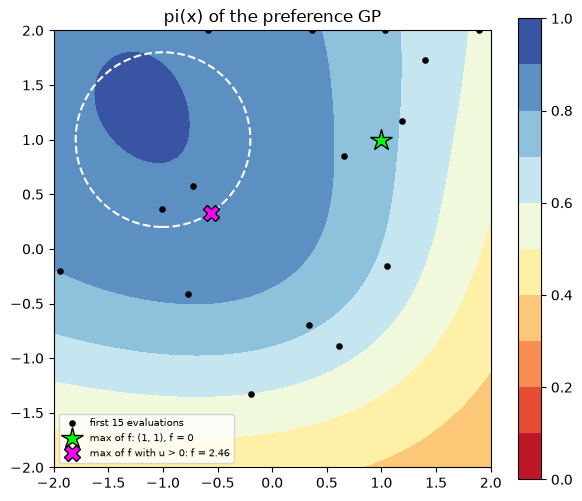

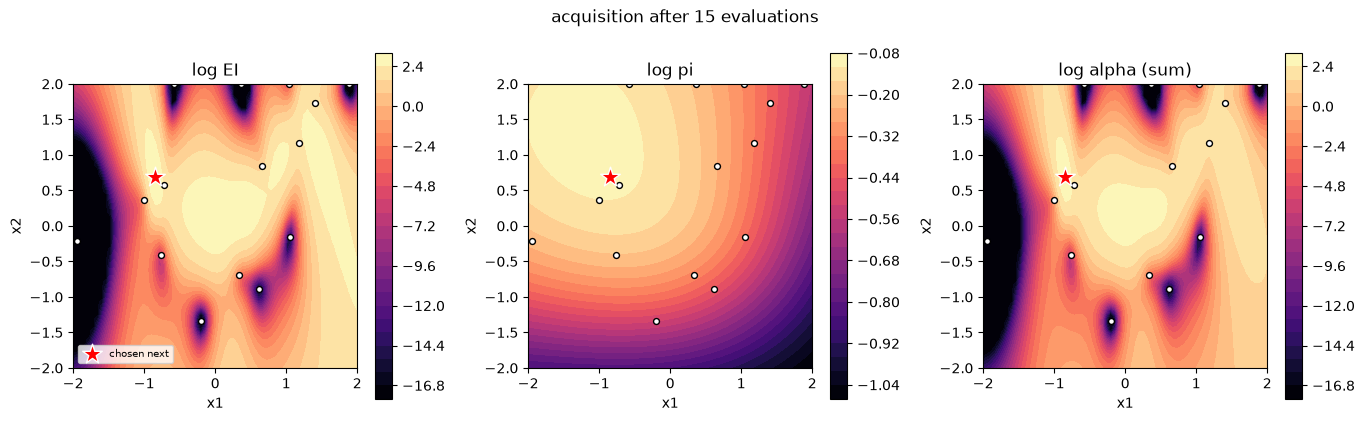

step 15: variation of each term over the box
  log EI  min  -1505.88   max    2.92   range   1508.80   sd   58.76   argmax at [-0.84  0.67]
  log pi  min     -1.08   max   -0.10   range      0.98   sd    0.25   argmax at [-1.19  1.3 ]
  pi: min 0.34, max 0.90;  share of the box with pi > 0.9: 4%, truly acceptable (u > 0): 12%


In [19]:
from IPython.display import display

step = 15
preference_gp = with_preference.models_at(step).preference
fig, axis = plt.subplots(figsize=(6.2, 5.2))
draw(axis, preference_gp.prob_torch(X_map).detach().numpy(), "pi(x) of the preference GP", "RdYlBu", np.linspace(0, 1, 11))
axis.scatter(*with_preference.X[:step].T, c="k", s=14, label=f"first {step} evaluations")
mark_optima(axis)
plt.tight_layout()
plt.show()
display(with_preference.plot_acquisition(n=step))

acquisition = with_preference.acquisition(step)
X_batch = torch.as_tensor(X_map[:, None, :], dtype=torch.float64)
with torch.no_grad():
    terms = {"log EI": acquisition.log_ei(X_batch).numpy(), "log pi": acquisition.log_pref(X_batch).numpy()}
pi_values = np.exp(terms["log pi"])
print(f"step {step}: variation of each term over the box")
for name, values in terms.items():
    print(f"  {name:7s} min {values.min():9.2f}   max {values.max():7.2f}   range {np.ptp(values):9.2f}   "
          f"sd {values.std():7.2f}   argmax at {np.round(X_map[np.argmax(values)], 2)}")
print(f"  pi: min {pi_values.min():.2f}, max {pi_values.max():.2f};  share of the box with pi > 0.9: {np.mean(pi_values > 0.9):.0%}, "
      f"truly acceptable (u > 0): {np.mean(utility(X_map) > 0):.0%}")

## Rosenbrock, with a more drastic cutoff in utility WORK IN PROGRESS

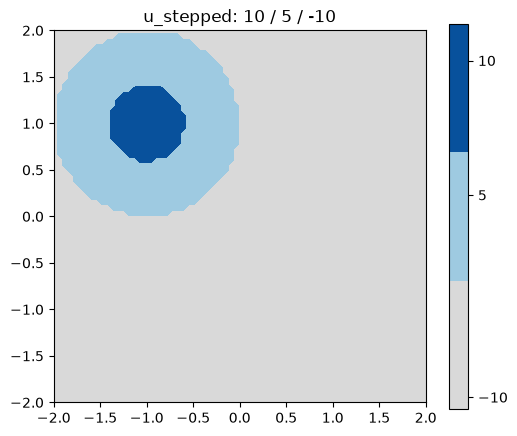

In [20]:
disc_centre, disc_radius = np.array([-1.0, 1.0]), 0.8                


def u_stepped(X):
    """Three levels around (-1, 1): 10 inside radius 0.5 * 0.8, 5 inside radius 1.25 * 0.8, -10 outside."""
    distance = np.linalg.norm(X - disc_centre, axis=1)
    return np.where(distance < 0.5 * disc_radius, 10.0, np.where(distance < 1.25 * disc_radius, 5.0, -10.0))


fig, axis = plt.subplots(figsize=(6, 5))
shown = axis.contourf(map_x1, map_x2, u_stepped(X_map).reshape(map_x1.shape), [-11, 0, 7.5, 11], colors=["#d9d9d9", "#9ecae1", "#08519c"])
fig.colorbar(shown, ax=axis, ticks=[-10, 5, 10])
axis.set_title("u_stepped: 10 / 5 / -10")
axis.set_aspect("equal")
plt.show()

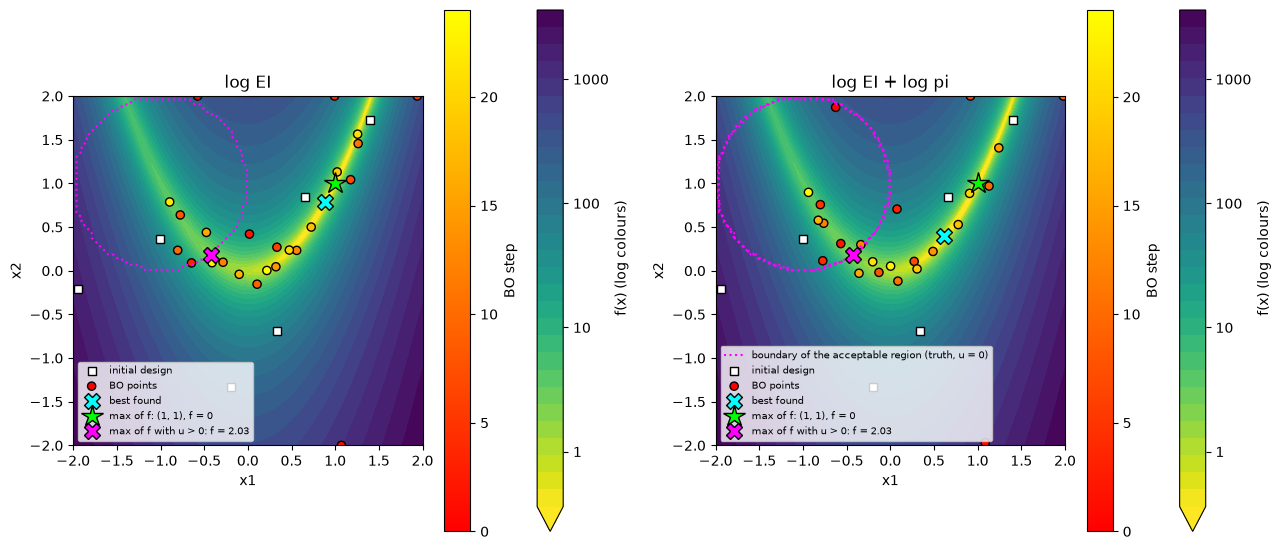

max of f: 0.0000 at (1, 1);  max of f with u > 0: 2.0325 at [-0.425  0.185]
log EI           BO points with u > 0:  20%;  best f among designs with u > 0: 3.3020
log EI + log pi  BO points with u > 0:  32%;  best f among designs with u > 0: 2.4682


In [21]:
x_acceptable_stepped, f_acceptable_stepped = grid_optimum(neg_rosenbrock, ROSEN_BOUNDS, accept=lambda X: u_stepped(X) > 0)
plain_stepped = BayesianOptimizer(neg_rosenbrock, ROSEN_BOUNDS, seed=0).run(n_bo_steps)
with_preference_stepped = BayesianOptimizer(neg_rosenbrock, ROSEN_BOUNDS, seed=0, comparer=NoisyPairwiseLabeler(u_stepped, sigma=0.5),
                                            X_pref=initial_design(ROSEN_BOUNDS, 30, "lhs", seed=7)).run(n_bo_steps)


def mark_optima_stepped(axis):
    axis.plot(1, 1, "*", color="lime", ms=16, mec="k", label="max of f: (1, 1), f = 0")
    axis.plot(*x_acceptable_stepped, "X", color="magenta", ms=11, mec="k", label=f"max of f with u > 0: f = {-f_acceptable_stepped:.2f}")
    axis.legend(fontsize=7, loc="lower left")


fig, axes = plt.subplots(1, 2, figsize=(13, 5.6))
for axis, run, name in zip(axes, (plain_stepped, with_preference_stepped), ("log EI", "log EI + log pi")):
    run.plot_points(ax=axis, background=rosenbrock, background_label="f(x)", background_scale="log", title=name)
    mark_optima_stepped(axis)
for axis in axes:
    axis.contour(map_x1, map_x2, u_stepped(X_map).reshape(map_x1.shape), [0], colors="magenta", linestyles=":")
plt.tight_layout()
plt.show()
print(f"max of f: 0.0000 at (1, 1);  max of f with u > 0: {-f_acceptable_stepped:.4f} at {np.round(x_acceptable_stepped, 3)}")
for name, run in (("log EI", plain_stepped), ("log EI + log pi", with_preference_stepped)):
    accepted = u_stepped(run.X) > 0
    print(f"{name:16s} BO points with u > 0: {np.mean(accepted[run.n_init:]):4.0%};  "
          f"best f among designs with u > 0: {-np.max(run.y[accepted]) if accepted.any() else float('nan'):.4f}")